# Part 3. 수요 예측

- 취소예측: "예약 한 건" = 한 행 → 분류
- 수요예측: "하루" = 한 행 → 시계열 회귀

데이터를 투숙일별로 집계해서 "그 날짜에 예약이 몇 건"을 만든다.
그리고 EDA에서 정한 대로 호텔별로 나눠서 예측한다. (City 우상향, Resort 평탄)

In [1]:
# 기본 구조 확인하기
import pandas as pd
import numpy as np

df = pd.read_csv('hotel_bookings.csv')

In [2]:
# 날짜 칼럼 재정의
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-'
    + df['arrival_date_month'] + '-'
    + df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2015-07-01


In [3]:
# ===== Part 3: 수요예측 =====
# 호텔별로 날짜별 집계 (총예약 / 실제투숙=순수요)
def make_daily(df, hotel_name):
    h = df[df['hotel'] == hotel_name].copy()
    daily = h.groupby('arrival_date').agg(
        total_bookings=('is_canceled', 'size'),
        actual_stays=('is_canceled', lambda x: (x==0).sum())
    ).reset_index().sort_values('arrival_date').reset_index(drop=True)
    return daily

city = make_daily(df, 'City Hotel')
resort = make_daily(df, 'Resort Hotel')

print("=== City ===")
print("기간:", city['arrival_date'].min().date(), "~", city['arrival_date'].max().date())
print("일수:", len(city))
print(city['actual_stays'].describe().round(1))
print("\n=== Resort ===")
print("일수:", len(resort))
print(resort['actual_stays'].describe().round(1))
print("\nCity head:")
print(city.head())

=== City ===
기간: 2015-07-01 ~ 2017-08-31
일수: 793
count    793.0
mean      58.3
std       27.6
min        0.0
25%       39.0
50%       59.0
75%       74.0
max      204.0
Name: actual_stays, dtype: float64

=== Resort ===
일수: 793
count    793.0
mean      36.5
std       15.6
min        4.0
25%       27.0
50%       35.0
75%       44.0
max      116.0
Name: actual_stays, dtype: float64

City head:
  arrival_date  total_bookings  actual_stays
0   2015-07-01              79            65
1   2015-07-02              49             1
2   2015-07-03              16            10
3   2015-07-04              38             9
4   2015-07-05               8             0


In [4]:
# 초반 안정화 구간 확인 (월별 평균으로 언제부터 정상인지)
city['ym'] = city['arrival_date'].dt.to_period('M')
print(city.groupby('ym')['actual_stays'].mean().round(1).head(8))

ym
2015-07    14.8
2015-08    40.3
2015-09    66.2
2015-10    66.6
2015-11    31.1
2015-12    31.8
2016-01    29.9
2016-02    49.7
Freq: M, Name: actual_stays, dtype: float64


In [5]:
# 2015-07 (좌측 절단) 제거, 2015-08부터 시작
city = city[city['arrival_date'] >= '2015-08-01'].reset_index(drop=True)
resort = resort[resort['arrival_date'] >= '2015-08-01'].reset_index(drop=True)

print("City 시작:", city['arrival_date'].min().date(), "일수:", len(city))
print(city['actual_stays'].describe().round(1))

City 시작: 2015-08-01 일수: 762
count    762.0
mean      60.1
std       26.4
min        4.0
25%       41.0
50%       60.0
75%       76.0
max      204.0
Name: actual_stays, dtype: float64


In [ ]:
# ===== Part 4: Feature Engineering =====
def add_features(daily, target='actual_stays'):
    d = daily.copy().sort_values('arrival_date').reset_index(drop=True)
    
    # 시간 피처
    d['dow'] = d['arrival_date'].dt.dayofweek      # 요일 0~6
    d['month'] = d['arrival_date'].dt.month         # 월 (계절성)
    d['is_weekend'] = (d['dow'] >= 5).astype(int)   # 주말 여부
    
    # lag (과거 값) — 자기상관 강했던 7, 14
    d['lag_7'] = d[target].shift(7)
    d['lag_14'] = d[target].shift(14)
    d['lag_1'] = d[target].shift(1)
    
    # rolling mean (최근 평균, 추세) — shift(1)로 당일 제외(누수 방지)
    d['roll_mean_7'] = d[target].shift(1).rolling(7).mean()
    d['roll_mean_14'] = d[target].shift(1).rolling(14).mean()
    
    return d

city_fe = add_features(city)
resort_fe = add_features(resort)

# lag 때문에 앞부분 NaN 생김 → 제거
city_fe = city_fe.dropna().reset_index(drop=True)
resort_fe = resort_fe.dropna().reset_index(drop=True)

print("City 피처 추가 후:", city_fe.shape)
print(city_fe[['arrival_date','actual_stays','dow','month','lag_7','roll_mean_7']].head())

City 피처 추가 후: (748, 12)
  arrival_date  actual_stays  dow  month  lag_7  roll_mean_7
0   2015-08-15            55    5      8   73.0    59.000000
1   2015-08-16            24    6      8   28.0    56.428571
2   2015-08-17            63    0      8   72.0    55.857143
3   2015-08-18            45    1      8   61.0    54.571429
4   2015-08-19            38    2      8   66.0    52.285714


In [7]:
# 시간순 분할 (수요예측도 과거→미래)
def split_time(d, train_ratio=0.7, valid_ratio=0.15):
    n = len(d)
    t1 = int(n * train_ratio)
    t2 = int(n * (train_ratio + valid_ratio))
    return d.iloc[:t1], d.iloc[t1:t2], d.iloc[t2:]

city_tr, city_va, city_te = split_time(city_fe)
print(f"train {len(city_tr)} | valid {len(city_va)} | test {len(city_te)}")
print(f"train: {city_tr['arrival_date'].min().date()} ~ {city_tr['arrival_date'].max().date()}")
print(f"test:  {city_te['arrival_date'].min().date()} ~ {city_te['arrival_date'].max().date()}")

train 523 | valid 112 | test 113
train: 2015-08-15 ~ 2017-01-18
test:  2017-05-11 ~ 2017-08-31


In [8]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

target = 'actual_stays'

# Naive: 어제 값 = 오늘 예측
naive_pred = city_te['lag_1']
# Seasonal Naive: 지난주 같은 요일 = 오늘 예측 (자기상관 최강)
snaive_pred = city_te['lag_7']

print("=== 베이스라인 (City test) ===")
print(f"Naive (어제):      MAE {mean_absolute_error(city_te[target], naive_pred):.2f} | "
      f"MAPE {mean_absolute_percentage_error(city_te[target], naive_pred):.3f}")
print(f"Seasonal (지난주): MAE {mean_absolute_error(city_te[target], snaive_pred):.2f} | "
      f"MAPE {mean_absolute_percentage_error(city_te[target], snaive_pred):.3f}")

=== 베이스라인 (City test) ===
Naive (어제):      MAE 20.37 | MAPE 0.302
Seasonal (지난주): MAE 17.83 | MAPE 0.266


In [9]:
import lightgbm as lgb

features = ['dow','month','is_weekend','lag_1','lag_7','lag_14','roll_mean_7','roll_mean_14']

X_tr, y_tr = city_tr[features], city_tr[target]
X_va, y_va = city_va[features], city_va[target]
X_te, y_te = city_te[features], city_te[target]

params_reg = {
    'objective': 'regression',   # 회귀! (취소예측은 binary였음)
    'metric': 'mae',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42,
}

lgb_tr = lgb.Dataset(X_tr, label=y_tr)
lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
model_city = lgb.train(params_reg, lgb_tr, num_boost_round=1000,
    valid_sets=[lgb_va], callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

pred = model_city.predict(X_te)
print("\n=== LightGBM (City test) ===")
print(f"MAE {mean_absolute_error(y_te, pred):.2f} | MAPE {mean_absolute_percentage_error(y_te, pred):.3f}")

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[32]	valid_0's l1: 14.4866

=== LightGBM (City test) ===
MAE 13.38 | MAPE 0.188


Resort도 동일하게 시행

In [10]:
# Resort도 동일하게
resort_tr, resort_va, resort_te = split_time(resort_fe)

X_tr, y_tr = resort_tr[features], resort_tr[target]
X_va, y_va = resort_va[features], resort_va[target]
X_te, y_te = resort_te[features], resort_te[target]

# 베이스라인
print("=== Resort 베이스라인 ===")
print(f"Seasonal (지난주): MAE {mean_absolute_error(resort_te[target], resort_te['lag_7']):.2f} | "
      f"MAPE {mean_absolute_percentage_error(resort_te[target], resort_te['lag_7']):.3f}")

# LightGBM
lgb_tr = lgb.Dataset(X_tr, label=y_tr)
lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
model_resort = lgb.train(params_reg, lgb_tr, num_boost_round=1000,
    valid_sets=[lgb_va], callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

pred = model_resort.predict(X_te)
print("=== Resort LightGBM ===")
print(f"MAE {mean_absolute_error(y_te, pred):.2f} | MAPE {mean_absolute_percentage_error(y_te, pred):.3f}")

=== Resort 베이스라인 ===
Seasonal (지난주): MAE 10.19 | MAPE 0.287
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[11]	valid_0's l1: 12.1349
=== Resort LightGBM ===
MAE 7.39 | MAPE 0.224


In [11]:
# on-the-books: 투숙일 기준 '리드타임 7일 이상'인 예약 수
# = 투숙 7일 전 시점에 이미 예약돼 있던 건수
def add_otb(df, hotel_name, days_before=7):
    h = df[df['hotel'] == hotel_name].copy()
    # 리드타임 >= days_before 인 예약만 = 그 시점에 이미 존재
    otb = h[h['lead_time'] >= days_before].groupby('arrival_date').size()
    return otb

# City에 OTB 피처 추가 (7일 전, 30일 전 시점)
for days in [7, 30]:
    otb = df[(df['hotel']=='City Hotel') & (df['lead_time']>=days)].groupby('arrival_date').size()
    city_fe[f'otb_{days}'] = city_fe['arrival_date'].map(otb).fillna(0)

for days in [7, 30]:
    otb = df[(df['hotel']=='Resort Hotel') & (df['lead_time']>=days)].groupby('arrival_date').size()
    resort_fe[f'otb_{days}'] = resort_fe['arrival_date'].map(otb).fillna(0)

print("City OTB 확인:")
print(city_fe[['arrival_date','actual_stays','otb_7','otb_30']].head())

City OTB 확인:
  arrival_date  actual_stays  otb_7  otb_30
0   2015-08-15            55    103    94.0
1   2015-08-16            24     11     7.0
2   2015-08-17            63     95    88.0
3   2015-08-18            45     28     4.0
4   2015-08-19            38     16     6.0


In [12]:
# OTB 포함해서 다시 학습 (City)
features_otb = ['dow','month','is_weekend','lag_1','lag_7','lag_14',
                'roll_mean_7','roll_mean_14','otb_7','otb_30']

city_tr, city_va, city_te = split_time(city_fe)
X_tr, y_tr = city_tr[features_otb], city_tr[target]
X_va, y_va = city_va[features_otb], city_va[target]
X_te, y_te = city_te[features_otb], city_te[target]

lgb_tr = lgb.Dataset(X_tr, label=y_tr)
lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
model_city_otb = lgb.train(params_reg, lgb_tr, num_boost_round=1000,
    valid_sets=[lgb_va], callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

pred = model_city_otb.predict(X_te)
print("=== City 비교 ===")
print(f"OTB 전:  MAE 13.38 | MAPE 0.188")
print(f"OTB 후:  MAE {mean_absolute_error(y_te, pred):.2f} | MAPE {mean_absolute_percentage_error(y_te, pred):.3f}")

# feature importance로 OTB가 실제 쓸모있었나 확인
imp = pd.DataFrame({
    'feature': model_city_otb.feature_name(),
    'gain': model_city_otb.feature_importance(importance_type='gain')
}).sort_values('gain', ascending=False)
print("\n=== 피처 중요도 ===")
print(imp.to_string(index=False))

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[26]	valid_0's l1: 11.7475
=== City 비교 ===
OTB 전:  MAE 13.38 | MAPE 0.188
OTB 후:  MAE 8.95 | MAPE 0.124

=== 피처 중요도 ===
     feature         gain
       otb_7 2.619126e+06
      otb_30 9.218123e+04
       lag_1 8.705662e+04
       lag_7 6.205772e+04
roll_mean_14 4.140946e+04
         dow 2.498050e+04
      lag_14 2.347734e+04
 roll_mean_7 2.108672e+04
       month 1.552503e+04
  is_weekend 0.000000e+00


In [13]:
# Resort도 OTB 포함
resort_tr, resort_va, resort_te = split_time(resort_fe)
X_tr, y_tr = resort_tr[features_otb], resort_tr[target]
X_va, y_va = resort_va[features_otb], resort_va[target]
X_te, y_te = resort_te[features_otb], resort_te[target]

lgb_tr = lgb.Dataset(X_tr, label=y_tr)
lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
model_resort_otb = lgb.train(params_reg, lgb_tr, num_boost_round=1000,
    valid_sets=[lgb_va], callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

pred = model_resort_otb.predict(X_te)
print("=== Resort 비교 ===")
print(f"OTB 전:  MAE 7.39 | MAPE 0.224")
print(f"OTB 후:  MAE {mean_absolute_error(y_te, pred):.2f} | MAPE {mean_absolute_percentage_error(y_te, pred):.3f}")

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[39]	valid_0's l1: 7.29398
=== Resort 비교 ===
OTB 전:  MAE 7.39 | MAPE 0.224
OTB 후:  MAE 5.90 | MAPE 0.180


In [14]:
# OTB를 여러 시점으로 (예약이 차는 pace)
otb_days = [3, 7, 14, 30, 60, 90]

for days in otb_days:
    otb_c = df[(df['hotel']=='City Hotel') & (df['lead_time']>=days)].groupby('arrival_date').size()
    city_fe[f'otb_{days}'] = city_fe['arrival_date'].map(otb_c).fillna(0)
    otb_r = df[(df['hotel']=='Resort Hotel') & (df['lead_time']>=days)].groupby('arrival_date').size()
    resort_fe[f'otb_{days}'] = resort_fe['arrival_date'].map(otb_r).fillna(0)

# pace 피처: 최근에 얼마나 빨리 찼나 (7일전 - 30일전)
city_fe['otb_pace'] = city_fe['otb_7'] - city_fe['otb_30']
resort_fe['otb_pace'] = resort_fe['otb_7'] - resort_fe['otb_30']

# 피처 목록 갱신
features_otb2 = ['dow','month','is_weekend','lag_1','lag_7','lag_14',
                 'roll_mean_7','roll_mean_14',
                 'otb_3','otb_7','otb_14','otb_30','otb_60','otb_90','otb_pace']

# City 재학습
city_tr, city_va, city_te = split_time(city_fe)
X_tr, y_tr = city_tr[features_otb2], city_tr[target]
X_va, y_va = city_va[features_otb2], city_va[target]
X_te, y_te = city_te[features_otb2], city_te[target]
lgb_tr = lgb.Dataset(X_tr, label=y_tr); lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
m = lgb.train(params_reg, lgb_tr, num_boost_round=1000, valid_sets=[lgb_va],
              callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
pred = m.predict(X_te)
print("=== City ===")
print(f"otb 2개:  MAPE 0.124")
print(f"otb pace: MAPE {mean_absolute_percentage_error(y_te, pred):.3f}")

# Resort 재학습
resort_tr, resort_va, resort_te = split_time(resort_fe)
X_tr, y_tr = resort_tr[features_otb2], resort_tr[target]
X_va, y_va = resort_va[features_otb2], resort_va[target]
X_te, y_te = resort_te[features_otb2], resort_te[target]
lgb_tr = lgb.Dataset(X_tr, label=y_tr); lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
m2 = lgb.train(params_reg, lgb_tr, num_boost_round=1000, valid_sets=[lgb_va],
               callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
pred2 = m2.predict(X_te)
print("=== Resort ===")
print(f"otb 2개:  MAPE 0.180")
print(f"otb pace: MAPE {mean_absolute_percentage_error(y_te, pred2):.3f}")

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[30]	valid_0's l1: 11.3966
=== City ===
otb 2개:  MAPE 0.124
otb pace: MAPE 0.122
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[48]	valid_0's l1: 6.60309
=== Resort ===
otb 2개:  MAPE 0.180
otb pace: MAPE 0.167


In [15]:
# feature importance로 otb_3 누수 여부 + pace 기여 확인 (City)
imp = pd.DataFrame({
    'feature': m.feature_name(),
    'gain': m.feature_importance(importance_type='gain')
}).sort_values('gain', ascending=False)
print(imp.to_string(index=False))

     feature         gain
       otb_3 2.556032e+06
       otb_7 1.773473e+05
      otb_90 1.328009e+05
       lag_1 7.634130e+04
    otb_pace 5.022407e+04
roll_mean_14 4.169927e+04
      otb_14 3.640029e+04
      otb_60 3.305930e+04
       lag_7 3.170660e+04
 roll_mean_7 2.036715e+04
      otb_30 1.824563e+04
         dow 1.606455e+04
      lag_14 1.501722e+04
       month 1.261492e+04
  is_weekend 0.000000e+00


In [16]:
# otb_3 제거 (누수 경계 + 실무 무의미)
features_final = ['dow','month','is_weekend','lag_1','lag_7','lag_14',
                  'roll_mean_7','roll_mean_14',
                  'otb_7','otb_14','otb_30','otb_60','otb_90','otb_pace']

# City
city_tr, city_va, city_te = split_time(city_fe)
X_tr, y_tr = city_tr[features_final], city_tr[target]
X_va, y_va = city_va[features_final], city_va[target]
X_te, y_te = city_te[features_final], city_te[target]
lgb_tr = lgb.Dataset(X_tr, label=y_tr); lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
m_city = lgb.train(params_reg, lgb_tr, num_boost_round=1000, valid_sets=[lgb_va],
              callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
pred_c = m_city.predict(X_te)

# Resort
resort_tr, resort_va, resort_te = split_time(resort_fe)
X_tr, y_tr = resort_tr[features_final], resort_tr[target]
X_va, y_va = resort_va[features_final], resort_va[target]
X_te, y_te = resort_te[features_final], resort_te[target]
lgb_tr = lgb.Dataset(X_tr, label=y_tr); lgb_va = lgb.Dataset(X_va, label=y_va, reference=lgb_tr)
m_resort = lgb.train(params_reg, lgb_tr, num_boost_round=1000, valid_sets=[lgb_va],
              callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
pred_r = m_resort.predict(X_te)

print("=== otb_3 제거 후 (최종) ===")
print(f"City   MAPE {mean_absolute_percentage_error(city_te[target], pred_c):.3f}")
print(f"Resort MAPE {mean_absolute_percentage_error(resort_te[target], pred_r):.3f}")

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[22]	valid_0's l1: 11.6841
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[43]	valid_0's l1: 6.81201
=== otb_3 제거 후 (최종) ===
City   MAPE 0.127
Resort MAPE 0.182


시각화

C:\Users\안서영\AppData\Local\Temp\ipykernel_6888\3110727787.py:17: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\안서영\AppData\Local\Temp\ipykernel_6888\3110727787.py:17: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\안서영\AppData\Local\Temp\ipykernel_6888\3110727787.py:17: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\안서영\AppData\Local\Temp\ipykernel_6888\3110727787.py:17: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\안서영\AppData\Local\Temp\ipykernel_6888\3110727787.py:17: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\안서영\AppData\Local\Temp\ipykernel_6888\3110727787.py:17: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans

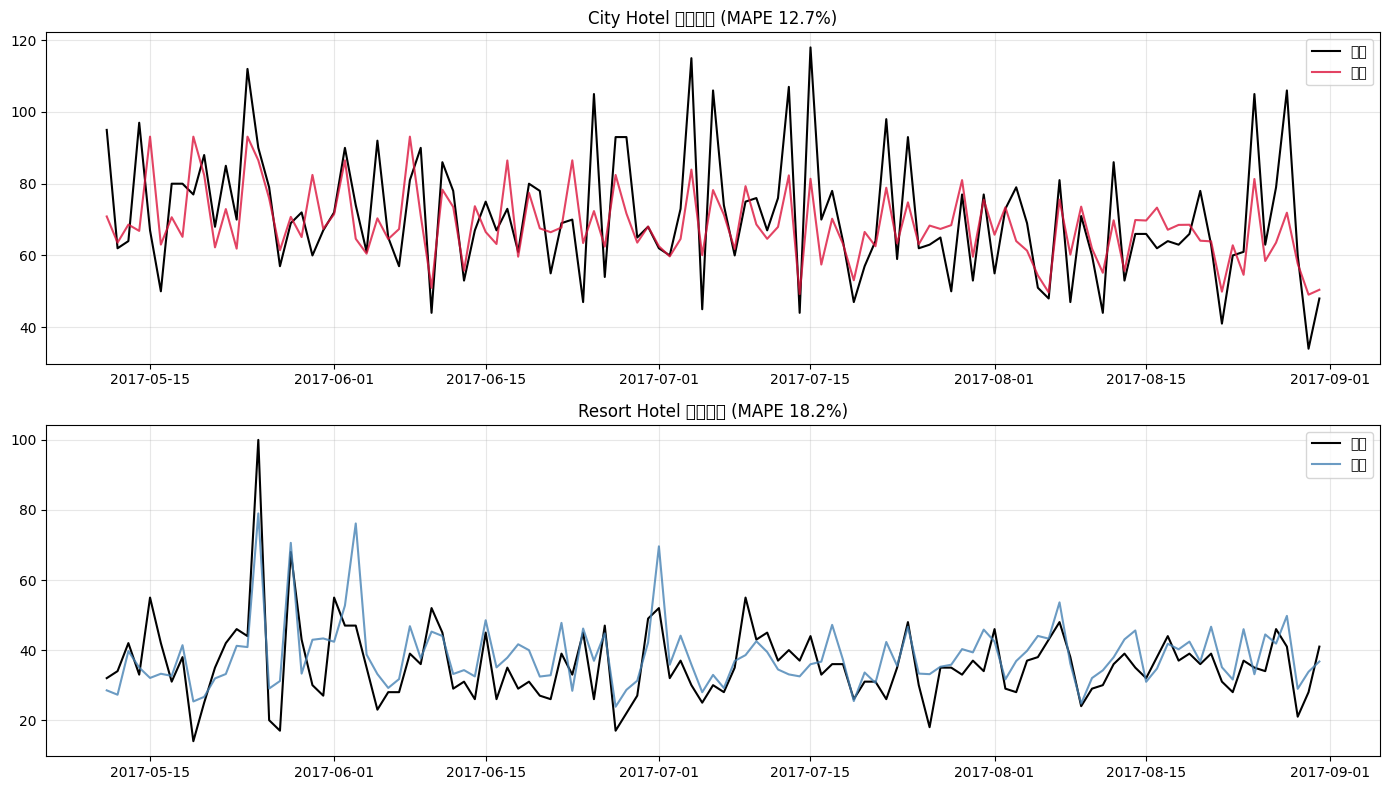

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# City
axes[0].plot(city_te['arrival_date'], city_te[target].values, label='실제', color='black', linewidth=1.5)
axes[0].plot(city_te['arrival_date'], pred_c, label='예측', color='crimson', linewidth=1.5, alpha=0.8)
axes[0].set_title(f'City Hotel 수요예측 (MAPE {mean_absolute_percentage_error(city_te[target], pred_c):.1%})')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Resort
axes[1].plot(resort_te['arrival_date'], resort_te[target].values, label='실제', color='black', linewidth=1.5)
axes[1].plot(resort_te['arrival_date'], pred_r, label='예측', color='steelblue', linewidth=1.5, alpha=0.8)
axes[1].set_title(f'Resort Hotel 수요예측 (MAPE {mean_absolute_percentage_error(resort_te[target], pred_r):.1%})')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('demand_forecast.png', dpi=120, bbox_inches='tight')
plt.show()